# Exploratory Data Analysis — Graph-Vul

This notebook explores the Graph-Vul dataset at two levels:
1. **Raw text** — source code and CVE descriptions from `subset_cwe119.csv`
2. **Processed data** — PyG graphs, DeBERTa embeddings, and train/val/test splits

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))

from graph_vul.config import DATA_DIR, PROCESSED_DIR, SPLITS_DIR, SUBSET_CSV

sns.set_theme(style="whitegrid")
%matplotlib inline

## Part 1 — Raw Text EDA

### 1.1 Dataset Overview

In [2]:
df = pd.read_csv(SUBSET_CSV)
print(f"Total samples: {len(df)}")
print(f"\nClass distribution:")
counts = df["vul"].value_counts()
for label, count in counts.items():
    name = "vulnerable" if label == 1 else "benign"
    print(f"  {name} ({label}): {count} ({count / len(df) * 100:.1f}%)")

df.head()

Total samples: 1000

Class distribution:
  benign (0): 500 (50.0%)
  vulnerable (1): 500 (50.0%)


,sample_id,func_before,cve_id,cve_desc,vul
0,0,int32 WebContentsImpl::GetMaxPageID() {\n ret...,CVE-2013-6626,The WebContentsImpl::AttachInterstitialPage fu...,0
1,1,"static bool cmd_read_native_max(IDEState *s, u...",CVE-2014-9718,The (1) BMDMA and (2) AHCI HBA interfaces in t...,0
2,2,void RenderViewHostImpl::WasSwappedOut() {\n ...,CVE-2013-0840,Google Chrome before 24.0.1312.56 does not val...,0
3,3,void WaitForResizeComplete(WebContents* web_co...,CVE-2018-6121,Insufficient validation of input in Blink in G...,0
4,4,static inline int l2cap_config_req(struct l2ca...,CVE-2017-1000251,The native Bluetooth stack in the Linux Kernel...,1


### 1.2 Code Text Statistics

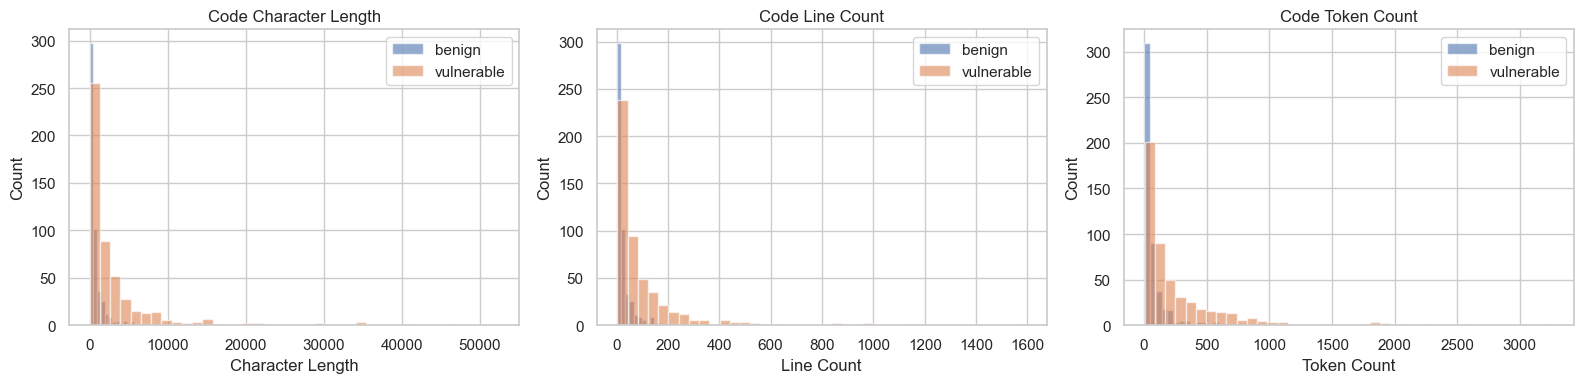

,code_char_len,code_line_count,code_token_count
count,1000.000000,1000.000000,1000.00000
mean,1976.126000,64.141000,174.13900
std,4387.976763,129.719089,330.92663
min,25.000000,2.000000,2.00000
25%,252.000000,10.000000,20.00000
50%,646.000000,21.500000,55.00000
75%,1819.500000,63.250000,179.00000
max,52461.000000,1595.000000,3269.00000


In [3]:
df["code_char_len"] = df["func_before"].str.len()
df["code_line_count"] = df["func_before"].str.count("\n") + 1
df["code_token_count"] = df["func_before"].str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(
    axes,
    ["code_char_len", "code_line_count", "code_token_count"],
    ["Character Length", "Line Count", "Token Count"],
):
    for label, group in df.groupby("vul"):
        name = "vulnerable" if label == 1 else "benign"
        ax.hist(group[col], bins=40, alpha=0.6, label=name)
    ax.set_title(f"Code {title}")
    ax.set_xlabel(title)
    ax.set_ylabel("Count")
    ax.legend()
plt.tight_layout()
plt.show()

df[["code_char_len", "code_line_count", "code_token_count"]].describe()

### 1.3 CVE Description Statistics

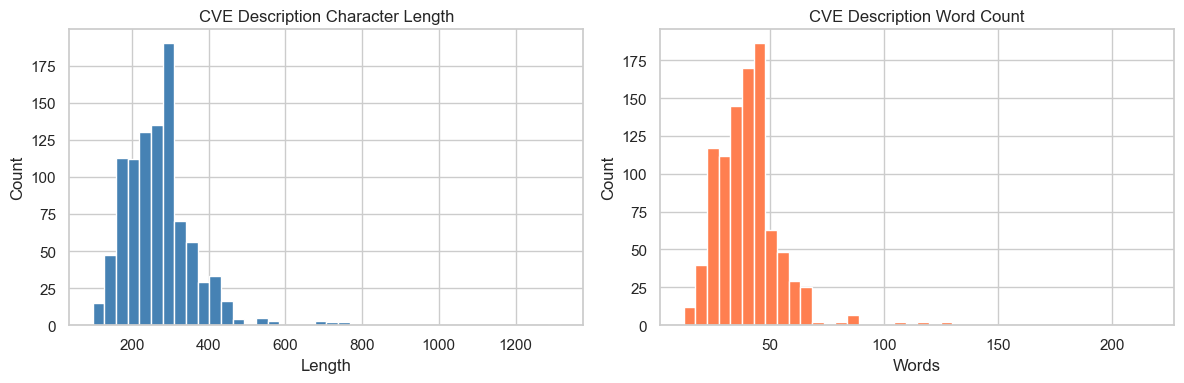

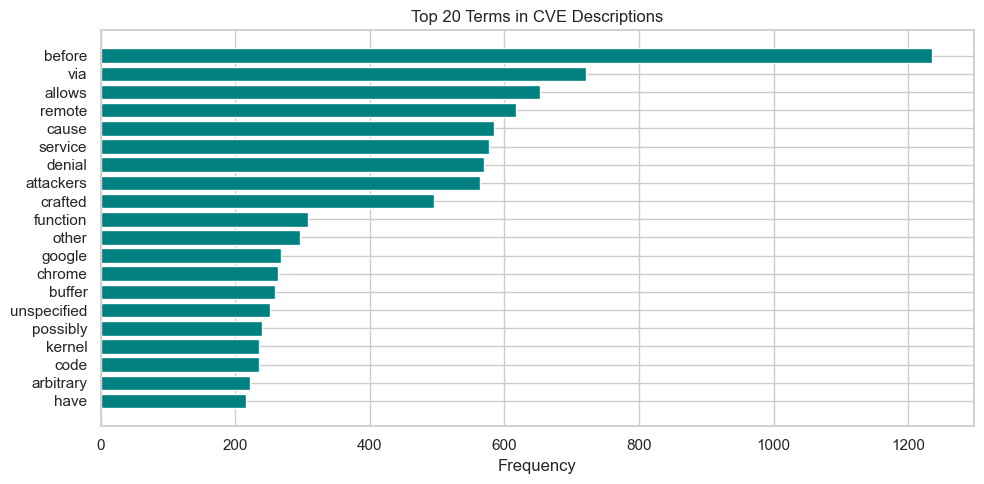

In [4]:
cve = df["cve_desc"].dropna()
df["cve_char_len"] = df["cve_desc"].str.len()
df["cve_word_count"] = df["cve_desc"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["cve_char_len"].dropna(), bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("CVE Description Character Length")
axes[0].set_xlabel("Length")
axes[0].set_ylabel("Count")

axes[1].hist(df["cve_word_count"].dropna(), bins=40, color="coral", edgecolor="white")
axes[1].set_title("CVE Description Word Count")
axes[1].set_xlabel("Words")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

# Top-20 most frequent terms (excluding common stopwords)
stopwords = {"the", "a", "an", "in", "to", "of", "and", "is", "for", "on", "that", "with", "by", "as", "or", "it", "be", "this", "from", "are", "was", "at", "not", "which", "but", "its"}
all_words = " ".join(cve).lower().split()
filtered = [w for w in all_words if w not in stopwords and len(w) > 2]
top20 = Counter(filtered).most_common(20)

fig, ax = plt.subplots(figsize=(10, 5))
words, counts = zip(*top20)
ax.barh(words[::-1], counts[::-1], color="teal")
ax.set_title("Top 20 Terms in CVE Descriptions")
ax.set_xlabel("Frequency")
plt.tight_layout()
plt.show()

## Part 2 — Processed Data EDA

### 2.1 Graph Structure Statistics

Loaded 1000 graphs


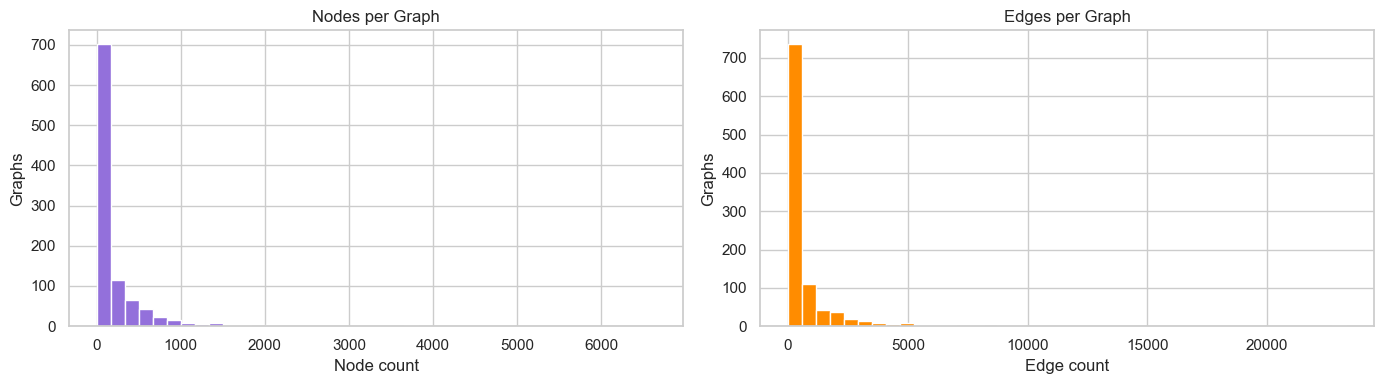

,nodes,edges
mean,213.725,742.084
median,50.500,117.500
min,8.000,8.000
max,6640.000,23298.000


In [5]:
import torch
from graph_vul.dataset.cpg_dataset import CPGDataset

dataset = CPGDataset()
print(f"Loaded {len(dataset)} graphs")

node_counts = []
edge_counts = []
labels = []
for i in range(len(dataset)):
    data = dataset[i]
    node_counts.append(data.num_nodes)
    edge_counts.append(data.edge_index.size(1))
    labels.append(int(data.y[0].item()))

node_counts = np.array(node_counts)
edge_counts = np.array(edge_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(node_counts, bins=40, color="mediumpurple", edgecolor="white")
axes[0].set_title("Nodes per Graph")
axes[0].set_xlabel("Node count")
axes[0].set_ylabel("Graphs")

axes[1].hist(edge_counts, bins=40, color="darkorange", edgecolor="white")
axes[1].set_title("Edges per Graph")
axes[1].set_xlabel("Edge count")
axes[1].set_ylabel("Graphs")
plt.tight_layout()
plt.show()

stats = pd.DataFrame({"nodes": node_counts, "edges": edge_counts})
stats.describe().loc[["mean", "50%", "min", "max"]].rename(index={"50%": "median"})

### 2.2 Edge Type Breakdown

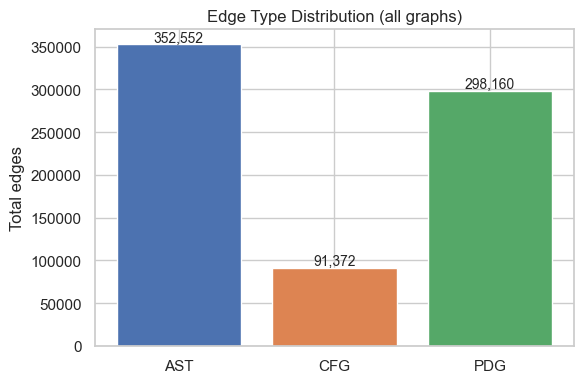

In [6]:
edge_type_names = {0: "AST", 1: "CFG", 2: "PDG"}
type_counts = Counter()
for i in range(len(dataset)):
    data = dataset[i]
    for t in data.edge_type.tolist():
        type_counts[t] += 1

names = [edge_type_names.get(k, f"type_{k}") for k in sorted(type_counts)]
values = [type_counts[k] for k in sorted(type_counts)]

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(names, values, color=["#4c72b0", "#dd8452", "#55a868"])
ax.set_title("Edge Type Distribution (all graphs)")
ax.set_ylabel("Total edges")
for i, v in enumerate(values):
    ax.text(i, v + max(values) * 0.01, f"{v:,}", ha="center", fontsize=10)
plt.tight_layout()
plt.show()

### 2.3 Embedding Analysis

Node embedding dim: 768
  mean: 0.0025, std: 0.5615
CVE embedding dim:  768
  mean: 0.0156, std: 1.0183


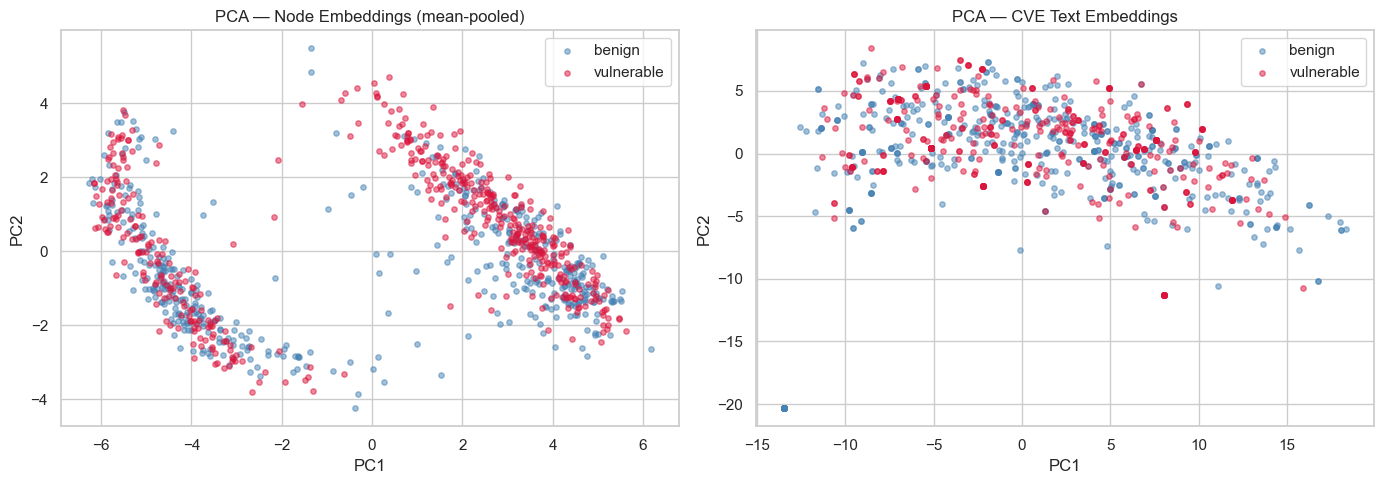

In [7]:
from sklearn.decomposition import PCA

# Collect graph-level embeddings: mean-pool node embeddings and CVE text vectors
node_emb_means = []
cve_embs = []
graph_labels = []
for i in range(len(dataset)):
    data = dataset[i]
    node_emb_means.append(data.x.mean(dim=0).numpy())
    cve_embs.append(data.text_vec.squeeze(0).numpy())
    graph_labels.append(int(data.y[0].item()))

node_emb_means = np.stack(node_emb_means)
cve_embs = np.stack(cve_embs)
graph_labels = np.array(graph_labels)

print(f"Node embedding dim: {node_emb_means.shape[1]}")
print(f"  mean: {node_emb_means.mean():.4f}, std: {node_emb_means.std():.4f}")
print(f"CVE embedding dim:  {cve_embs.shape[1]}")
print(f"  mean: {cve_embs.mean():.4f}, std: {cve_embs.std():.4f}")

# PCA projections
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, embs, title in zip(
    axes,
    [node_emb_means, cve_embs],
    ["Node Embeddings (mean-pooled)", "CVE Text Embeddings"],
):
    proj = PCA(n_components=2).fit_transform(embs)
    for label, color, name in [(0, "steelblue", "benign"), (1, "crimson", "vulnerable")]:
        mask = graph_labels == label
        ax.scatter(proj[mask, 0], proj[mask, 1], alpha=0.5, s=15, c=color, label=name)
    ax.set_title(f"PCA — {title}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend()

plt.tight_layout()
plt.show()

### 2.4 Train / Val / Test Split Statistics

      total vulnerable benign vul_ratio
train   700        350    350     50.0%
val     150         75     75     50.0%
test    150         75     75     50.0%


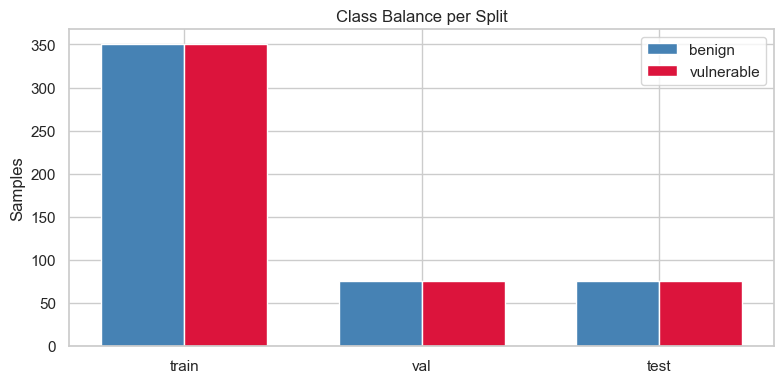

In [8]:
split_stats = {}
for split_name in ["train", "val", "test"]:
    ids = json.loads((SPLITS_DIR / f"{split_name}.json").read_text())
    split_df = df[df["sample_id"].isin(ids)]
    vul_count = split_df["vul"].sum()
    total = len(split_df)
    split_stats[split_name] = {
        "total": total,
        "vulnerable": int(vul_count),
        "benign": total - int(vul_count),
        "vul_ratio": f"{vul_count / total * 100:.1f}%" if total > 0 else "N/A",
    }

split_table = pd.DataFrame(split_stats).T
print(split_table.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(split_stats))
width = 0.35
ax.bar(x - width / 2, split_table["benign"], width, label="benign", color="steelblue")
ax.bar(x + width / 2, split_table["vulnerable"], width, label="vulnerable", color="crimson")
ax.set_xticks(x)
ax.set_xticklabels(split_table.index)
ax.set_ylabel("Samples")
ax.set_title("Class Balance per Split")
ax.legend()
plt.tight_layout()
plt.show()

### 2.5 Sample Graph Visualization

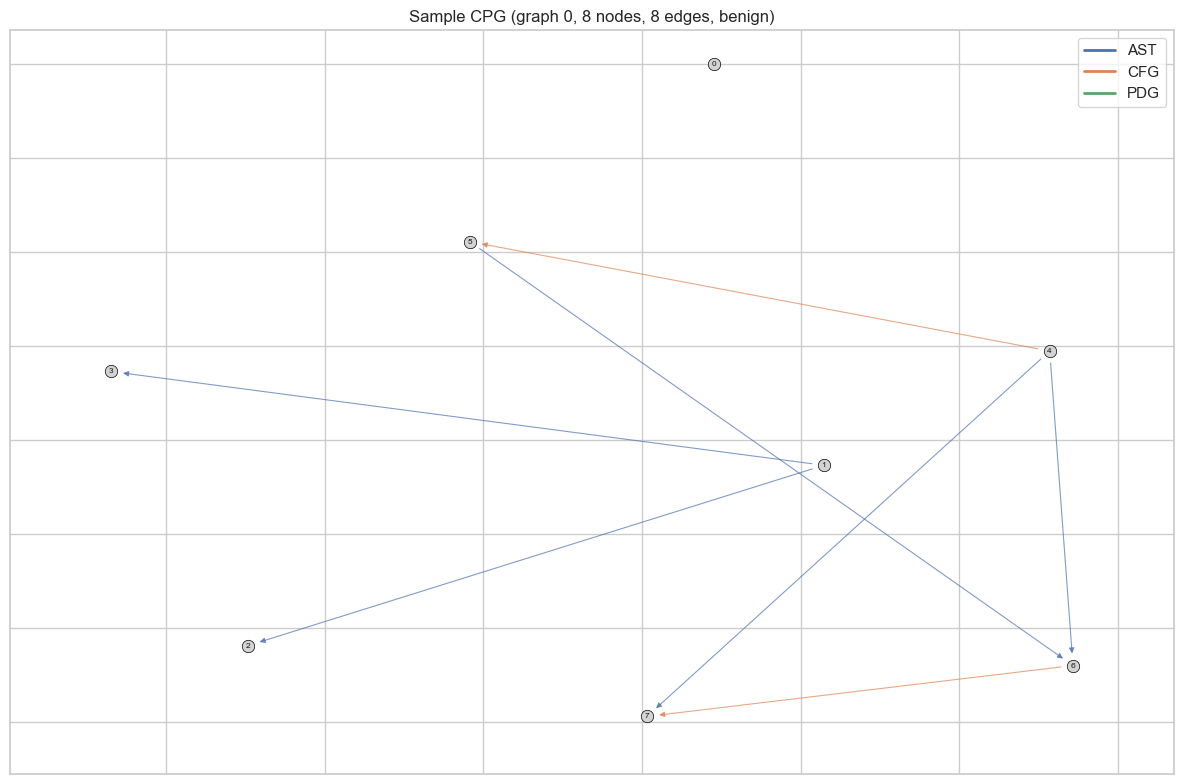

In [9]:
import networkx as nx

sample = dataset[0]
edge_color_map = {0: "#4c72b0", 1: "#dd8452", 2: "#55a868"}  # AST, CFG, PDG

G = nx.DiGraph()
G.add_nodes_from(range(sample.num_nodes))
edge_colors = []
for i in range(sample.edge_index.size(1)):
    src = sample.edge_index[0, i].item()
    dst = sample.edge_index[1, i].item()
    etype = sample.edge_type[i].item()
    G.add_edge(src, dst, edge_type=etype)
    edge_colors.append(edge_color_map.get(etype, "gray"))

fig, ax = plt.subplots(figsize=(12, 8))
pos = nx.spring_layout(G, seed=42, k=2.0)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=80, node_color="lightgray", edgecolors="black", linewidths=0.5)
nx.draw_networkx_edges(G, pos, ax=ax, edge_color=edge_colors, arrows=True, arrowsize=8, width=0.8, alpha=0.7)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=6)

# Legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color="#4c72b0", lw=2, label="AST"),
    Line2D([0], [0], color="#dd8452", lw=2, label="CFG"),
    Line2D([0], [0], color="#55a868", lw=2, label="PDG"),
]
ax.legend(handles=legend_elements, loc="upper right")
label_str = "vulnerable" if sample.y[0].item() == 1 else "benign"
ax.set_title(f"Sample CPG (graph 0, {sample.num_nodes} nodes, {sample.edge_index.size(1)} edges, {label_str})")
plt.tight_layout()
plt.show()